# Dupire Calibration : An implementation

This notebook aims to introduce the Dupire model through an implementation and a calibration on real data. For further information please have a look to my website. This notebook has been built with the following script : Dupire.py, following the same strategy as the Heston model. We will use the CAC 40 implied vol surface

In [21]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.interpolate import PchipInterpolator

from forward_curve import ForwardCurve
from Black_Scholes import BlackScholes
from ImpliedVolatilitySurface import ImpliedVolatilitySurface
from Heston import HestonModel
from Heston import TimeDependentHestonModel
from error import CalibrationLoss
from optimizer import Calibrator
from scipy.stats import norm

## 1. Market data

In [22]:
eq_underlying = "CAC40"
S0 = 8042.19
as_of_date = datetime.date(2025, 2, 12)

df_rates = pd.read_csv("../Data/EURIBOR6M_ZCRates_12022025.csv")
df_options = pd.read_csv("../Data/CAC40_MarketOptions_12022025.csv")
zc_rate = PchipInterpolator(df_rates['Expiry'], df_rates['ZCRate'], extrapolate=True)

def third_friday(month, year):
    result = datetime.date(year, month, 15)
    return result.replace(day=15 + (4 - result.weekday()) % 7)

months_nb = {m: i + 1 for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                             "August", "September", "October", "November", "December"])}
def year_fraction(label):
    month, year = label.split("-")
    return (third_friday(months_nb[month], int(year)) - as_of_date).days / 365

df_options['Expiry'] = df_options['Expiry'].apply(year_fraction)
df_options = df_options.sort_values(['Expiry', 'Strike'])
listed_expiries = list(df_options['Expiry'].unique())
market_strikes = {T: list(g['Strike']) for T, g in df_options.groupby('Expiry')}
call_prices = {T: list(g['Call']) for T, g in df_options.groupby('Expiry')}
put_prices = {T: list(g['Put']) for T, g in df_options.groupby('Expiry')}

## 2. Implied forwards and market implied volatility surface (OTM options)

Implied forward prices :
Expiry 0.0247 : The implied forward is 8048.9992
Expiry 0.1014 : The implied forward is 8066.5029
Expiry 0.1781 : The implied forward is 8079.0076
Expiry 0.3507 : The implied forward is 7943.4967
Expiry 0.6000 : The implied forward is 7987.5051
Expiry 0.8493 : The implied forward is 8003.0029
Expiry 1.0986 : The implied forward is 8039.0017
Expiry 1.3479 : The implied forward is 7931.0008
Expiry 1.5973 : The implied forward is 7944.0029
Expiry 1.8466 : The implied forward is 7969.9974
Expiry 2.8438 : The implied forward is 7897.9984
Expiry 3.8411 : The implied forward is 7872.9996
Expiry 4.8575 : The implied forward is 7847.4946

And its corresponding "Borrow + Dividend" curve :


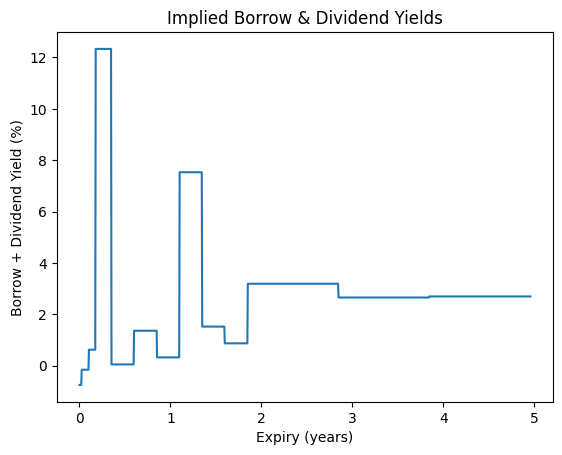

In [23]:
forward_curve = ForwardCurve(S0, zc_rate, listed_expiries, market_strikes, call_prices, put_prices)

otm_options = {T: [p if K <= forward_curve.implied_forwards[T] else c
                   for K, c, p in zip(market_strikes[T], call_prices[T], put_prices[T])]
               for T in listed_expiries}
bs_model = BlackScholes(zc_rate, forward_curve)
market_iv_surface = ImpliedVolatilitySurface(forward_curve, bs_model)
market_iv_surface.set_implied_vol_surface(market_strikes, otm_options)

In [24]:
vol_quotes = pd.DataFrame([
    {"T": T, "K": K, "F": forward_curve.implied_forwards[T], "IV": iv}
    for T in market_iv_surface.expiries
    for K, iv in zip(market_iv_surface.strikes[T], market_iv_surface.implied_vols[T])])
vol_quotes["log_moneyness"] = np.log(vol_quotes["K"] / vol_quotes["F"])
vol_quotes

,T,K,F,IV,log_moneyness
0,0.024658,7925.0,8048.999199,0.147886,-0.015525
1,0.024658,7950.0,8048.999199,0.144939,-0.012376
2,0.024658,7975.0,8048.999199,0.141802,-0.009236
3,0.024658,8000.0,8048.999199,0.138507,-0.006106
4,0.024658,8025.0,8048.999199,0.136136,-0.002986
...,...,...,...,...,...
137,4.857534,8000.0,7847.494553,0.168487,0.019247
138,4.857534,8400.0,7847.494553,0.163171,0.068037
139,4.857534,8800.0,7847.494553,0.159247,0.114557
140,4.857534,9600.0,7847.494553,0.154873,0.201569


## 3. Dupire calibration :


**Dynamics** under the risk-neutral measure:

$$\frac{dS_t}{S_t} = (r - q)\,dt + \sigma_{loc}(S_t, t)\,dW_t$$

**Dupire formula** (in call prices):

$$\sigma_{loc}^2(K,T) = \frac{\partial_T C + (r - q)\,K\,\partial_K C + q\,C}{\frac{1}{2}K^2\,\partial_{KK} C}$$

**Dupire formula** (in total implied variance), with $k = \ln(K/F_T)$ and $w(k,T) = \sigma_{imp}^2(k,T)\,T$:

$$\sigma_{loc}^2(k,T) = \frac{\partial_T w}{1 - \frac{k}{w}\partial_k w + \frac{1}{4}\left(-\frac{1}{4} - \frac{1}{w} + \frac{k^2}{w^2}\right)(\partial_k w)^2 + \frac{1}{2}\partial_{kk} w}$$

**No-arbitrage conditions**

- Calendar: $\partial_T w \geq 0$
- Butterfly: $g(k) = \left(1 - \frac{k w'}{2w}\right)^2 - \frac{w'^2}{4}\left(\frac{1}{w} + \frac{1}{4}\right) + \frac{w''}{2} \geq 0$

**Raw SVI** (one slice per maturity):

$$w(k) = a + b\left(\rho\,(k - m) + \sqrt{(k - m)^2 + \sigma^2}\right)$$

with $b \geq 0$, $|\rho| < 1$, $\sigma > 0$, $a + b\,\sigma\sqrt{1 - \rho^2} \geq 0$.

**Calibration** (for each maturity $T_j$):

$$\min_{a,b,\rho,m,\sigma} \sum_i \omega_i \left(w(k_i) - \sigma_{mkt,i}^2\,T_j\right)^2$$



In [25]:
import copy

class DupireModel:


    def __init__(self, zc_rate, forward_curve, a = 3, b = 0.04, m = 1 , rho = 0.6, sigma = 0.04 ):


        """
        Dupire Model variables initialization:

        Dupire parameters :

     
        """


        self.sc_rate = zc_rate
        self.forward_curve = forward_curve
        self.sigma = sigma
        self.a = a
        self.b = b
        self.rho = rho
        self.m = m

    @property
    def params(self):
        return {"v0" : self.v0, "theta" : self.theta, "kappa" : self.kappa, "xi": self.xi, "rho": self.rho}




    
        

## 4. Dupire in call prices : a naive implementation

The aim of this section is to apply the Dupire formula **directly on call prices**,

$$\sigma_{loc}^2(K,T) = \frac{\partial_T C + (r - q)\,K\,\partial_K C + q\,C}{\frac{1}{2}K^2\,\partial_{KK} C},$$

with finite differences, and to see where and why it fails. The same formula is applied to three inputs, from the roughest to the smoothest :
1. the **raw market quotes** (13 expiries, 11 strikes each) ;
2. call prices on a regular $(T, K)$ grid, priced with the **linearly interpolated** market implied vols (`method='v2t'`) ;
3. call prices on the same grid, priced with the **SSVI** fit of the implied vol surface.

**Diagnostics** : each point of the surface is checked against the no-arbitrage conditions written in prices
- calendar : numerator $\partial_T C + (r - q) K \partial_K C + q C \geq 0$,
- butterfly : denominator $\frac{1}{2}K^2 \partial_{KK} C \geq 0$ (it is the discounted risk-neutral density, Breeden-Litzenberger),

and the local vol must stay in a plausible range, here $[1\%, 150\%]$.

**Rates** : $r(T)$ and $q(T)$ are the *instantaneous* rates, $r(T) = \partial_T (R(T)\,T)$ with $R$ the zero-coupon rate, and $r(T) - q(T) = \partial_T \ln F(0,T)$.

### 4.1 Finite-difference Dupire and diagnostics

In [26]:
def instantaneous_rates(T, dt=1e-4):
    """
    Instantaneous rates at T, by central differences :
    r(T) = d(R(T) T)/dT,  mu(T) = r(T) - q(T) = d ln F(0,T) / dT.  Returns (r, q).
    """
    T = np.atleast_1d(np.asarray(T, dtype=float))
    up, dn = T + dt, np.maximum(T - dt, 1e-8)
    r = (zc_rate(up) * up - zc_rate(dn) * dn) / (up - dn)
    ln_fwd = lambda t: np.log([forward_curve.calc_forward(float(x)) for x in t])
    mu = (ln_fwd(up) - ln_fwd(dn)) / (up - dn)
    return r, r - mu


def dupire_from_price_grid(C, T, K):
    """
    Dupire local variance from a call price grid C[i, j] = C(T_i, K_j), K uniform.
    dC/dT : np.gradient (central inside, one-sided on the edges) ; dC/dK, d2C/dK2 : 3-point central differences,
    so the first and last strikes are NaN. Returns (numerator, denominator, local variance).
    """
    dK = K[1] - K[0]
    dC_dT = np.gradient(C, T, axis=0)
    dC_dK = np.full_like(C, np.nan)
    d2C_dK2 = np.full_like(C, np.nan)
    dC_dK[:, 1:-1] = (C[:, 2:] - C[:, :-2]) / (2 * dK)
    d2C_dK2[:, 1:-1] = (C[:, 2:] - 2 * C[:, 1:-1] + C[:, :-2]) / dK**2
    r, q = instantaneous_rates(T)
    r, q, KK = r[:, None], q[:, None], K[None, :]
    numerator = dC_dT + (r - q) * KK * dC_dK + q * C
    denominator = 0.5 * KK**2 * d2C_dK2
    with np.errstate(divide='ignore', invalid='ignore'):
        local_var = numerator / denominator
    return numerator, denominator, local_var


def local_vol_from_var(local_var):
    """sqrt of the local variance, NaN where it is not positive or not finite (0 denominator)."""
    local_var = np.asarray(local_var, dtype=float)
    with np.errstate(invalid='ignore'):
        return np.sqrt(np.where(np.isfinite(local_var) & (local_var > 0), local_var, np.nan))


def arbitrage_flags(numerator, denominator, local_var, vol_min=0.01, vol_max=1.5):
    """
    Point-wise diagnostic : 0 = valid, 1 = calendar arbitrage (numerator < 0),
    2 = butterfly arbitrage (denominator <= 0), 3 = local vol outside [vol_min, vol_max]. NaN where not computable.
    """
    numerator, denominator = np.asarray(numerator, dtype=float), np.asarray(denominator, dtype=float)
    local_vol = local_vol_from_var(local_var)
    flags = np.zeros(numerator.shape)
    flags[~((local_vol >= vol_min) & (local_vol <= vol_max))] = 3
    flags[numerator < 0] = 1
    flags[denominator <= 0] = 2
    flags[~np.isfinite(denominator) | ~np.isfinite(numerator)] = np.nan
    return flags


def diagnostics(flags, name):
    """Share (%) of each type of failure among the computable points."""
    f = flags[np.isfinite(flags)]
    return pd.Series({"points": f.size,
                      "valid (%)": 100 * np.mean(f == 0),
                      "calendar arbitrage (%)": 100 * np.mean(f == 1),
                      "butterfly arbitrage (%)": 100 * np.mean(f == 2),
                      "local vol out of range (%)": 100 * np.mean(f == 3)}, name=name)

### 4.2 Directly on the market quotes

The strikes are not on a regular grid and differ from one expiry to the next, so :
- $\partial_K C$ and $\partial_{KK} C$ use the non-uniform 3-point formulas on the strikes of the expiry ;
- $\partial_T C$ uses the previous and next expiries, linearly interpolated in $K$ at the same strike (NaN if the strike is not quoted on both sides).

The first and last expiries, and the first and last strikes of each expiry, cannot be computed.

In [27]:
rows = []
for j in range(1, len(listed_expiries) - 1):
    T_prev, T, T_next = listed_expiries[j - 1], listed_expiries[j], listed_expiries[j + 1]
    K_j, C_j = np.array(market_strikes[T]), np.array(call_prices[T])
    r, q = (x[0] for x in instantaneous_rates(T))
    for i in range(1, len(K_j) - 1):
        K, h_m, h_p = K_j[i], K_j[i] - K_j[i - 1], K_j[i + 1] - K_j[i]
        C_m, C_0, C_p = C_j[i - 1], C_j[i], C_j[i + 1]
        dC_dK = (C_p - C_m) / (h_p + h_m)
        d2C_dK2 = 2 * ((C_p - C_0) / h_p - (C_0 - C_m) / h_m) / (h_p + h_m)
        C_at = lambda t: np.interp(K, market_strikes[t], call_prices[t], left=np.nan, right=np.nan)
        dC_dT = (C_at(T_next) - C_at(T_prev)) / (T_next - T_prev)
        numerator = dC_dT + (r - q) * K * dC_dK + q * C_0
        denominator = 0.5 * K**2 * d2C_dK2
        rows.append({"T": T, "K": K, "C": C_0, "dC/dT": dC_dT, "dC/dK": dC_dK, "d2C/dK2": d2C_dK2,
                     "numerator": numerator, "denominator": denominator, "local_var": numerator / denominator})
raw_dupire = pd.DataFrame(rows)
raw_dupire["flag"] = arbitrage_flags(raw_dupire["numerator"], raw_dupire["denominator"], raw_dupire["local_var"])
raw_dupire["local_vol"] = local_vol_from_var(raw_dupire["local_var"])
raw_dupire = raw_dupire.merge(vol_quotes[["T", "K", "IV"]], on=["T", "K"], how="left")
raw_dupire.round(5)

,T,K,C,dC/dT,dC/dK,d2C/dK2,numerator,denominator,local_var,flag,local_vol,IV
0,0.10137,7850.0,286.62,NaN,-0.77140,0.00078,NaN,23909.53000,NaN,NaN,NaN,0.15414
1,0.10137,7900.0,249.02,NaN,-0.73190,0.00080,NaN,25088.82000,NaN,NaN,NaN,0.15008
2,0.10137,7950.0,213.43,884.99464,-0.68220,0.00118,753.76376,37415.88000,0.02015,0.0,0.14194,0.14605
3,0.10137,8000.0,180.80,904.28750,-0.62640,0.00105,782.99514,33536.00000,0.02335,0.0,0.15280,0.14273
4,0.10137,8050.0,150.79,903.04911,-0.56880,0.00126,792.18871,40695.97000,0.01947,0.0,0.13952,0.13952
...,...,...,...,...,...,...,...,...,...,...,...,...
94,3.84110,8000.0,886.26,95.43136,-0.47344,0.00018,131.18863,5882.00000,0.02230,0.0,0.14934,0.16665
95,3.84110,8400.0,711.59,99.14592,-0.39960,0.00019,128.86191,6540.03000,0.01970,0.0,0.14037,0.16082
96,3.84110,8800.0,566.58,100.11925,-0.29204,0.00018,123.45244,6822.78667,0.01809,0.0,0.13451,0.15653
97,3.84110,9600.0,361.14,94.21966,-0.19802,0.00015,109.93024,6771.60000,0.01623,0.0,0.12741,0.15285


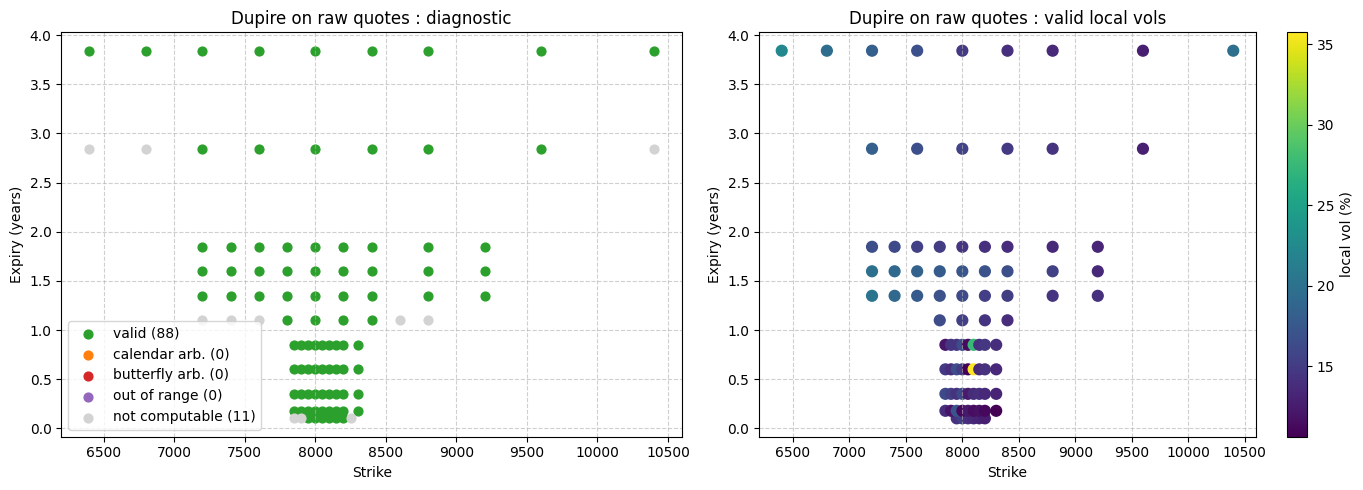

In [28]:
flag_labels = {0: "valid", 1: "calendar arb.", 2: "butterfly arb.", 3: "out of range"}
flag_colors = {0: "tab:green", 1: "tab:orange", 2: "tab:red", 3: "tab:purple"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for f, label in flag_labels.items():
    sub = raw_dupire[raw_dupire["flag"] == f]
    ax.scatter(sub["K"], sub["T"], color=flag_colors[f], label=f"{label} ({len(sub)})", s=40)
sub = raw_dupire[raw_dupire["flag"].isna()]
ax.scatter(sub["K"], sub["T"], color="lightgrey", label=f"not computable ({len(sub)})", s=40)
ax.set_xlabel("Strike"); ax.set_ylabel("Expiry (years)"); ax.set_title("Dupire on raw quotes : diagnostic")
ax.legend(); ax.grid(True, linestyle='--', alpha=0.6)

ax = axes[1]
ok = raw_dupire[raw_dupire["flag"] == 0]
sc = ax.scatter(ok["K"], ok["T"], c=100 * ok["local_vol"], cmap="viridis", s=60)
fig.colorbar(sc, ax=ax, label="local vol (%)")
ax.set_xlabel("Strike"); ax.set_ylabel("Expiry (years)"); ax.set_title("Dupire on raw quotes : valid local vols")
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout(); plt.show()

The CAC40 quotes are clean : every computable point passes the calendar and butterfly tests. But passing the
no-arbitrage tests does not make the local vol right : with 11 strikes per expiry, spaced by up to 800 points on the
long expiries, the finite differences are very coarse, and $\partial_T C$ mixes two expiries whose strike grids barely overlap.
The quality of these local vols is measured against the SSVI local vol in section 4.5.

### 4.3 On a regular grid : linearly interpolated implied vols

Call prices are now computed on a regular $(T, K)$ grid with the Black formula, the implied vol being the market one
interpolated with `get_vol(method='v2t')` : linear in $K$, linear in total variance in $T$, flat extrapolation.

In [29]:
T_grid = np.linspace(0.1, 4.8, 80)
K_grid = np.linspace(0.75 * S0, 1.25 * S0, 81)          # dK ~ 50 points

def call_price_grid(vol_func, T_axis=None, K_axis=None):
    """C[i, j] = Black call price at (T_i, K_j) with the implied vol vol_func(T, K)."""
    T_axis = T_grid if T_axis is None else T_axis
    K_axis = K_grid if K_axis is None else K_axis
    return np.array([[bs_model.bs_price_vanilla(T, K, vol_func(T, K), True) for K in K_axis] for T in T_axis])

iv_v2t = lambda T, K: float(market_iv_surface.get_vol(T, K, method='v2t'))
C_v2t = call_price_grid(iv_v2t)
num_v2t, den_v2t, lvar_v2t = dupire_from_price_grid(C_v2t, T_grid, K_grid)
flags_v2t = arbitrage_flags(num_v2t, den_v2t, lvar_v2t)

### 4.4 On a regular grid : SSVI implied vols

In [30]:
market_iv_surface.fit_ssvi()
iv_ssvi = lambda T, K: float(market_iv_surface.get_vol(T, K, method='ssvi'))
C_ssvi = call_price_grid(iv_ssvi)
num_ssvi, den_ssvi, lvar_ssvi = dupire_from_price_grid(C_ssvi, T_grid, K_grid)
flags_ssvi = arbitrage_flags(num_ssvi, den_ssvi, lvar_ssvi)

SSVI fit : RMSE = 0.218 vol pts


### 4.5 Local volatility surfaces and diagnostics

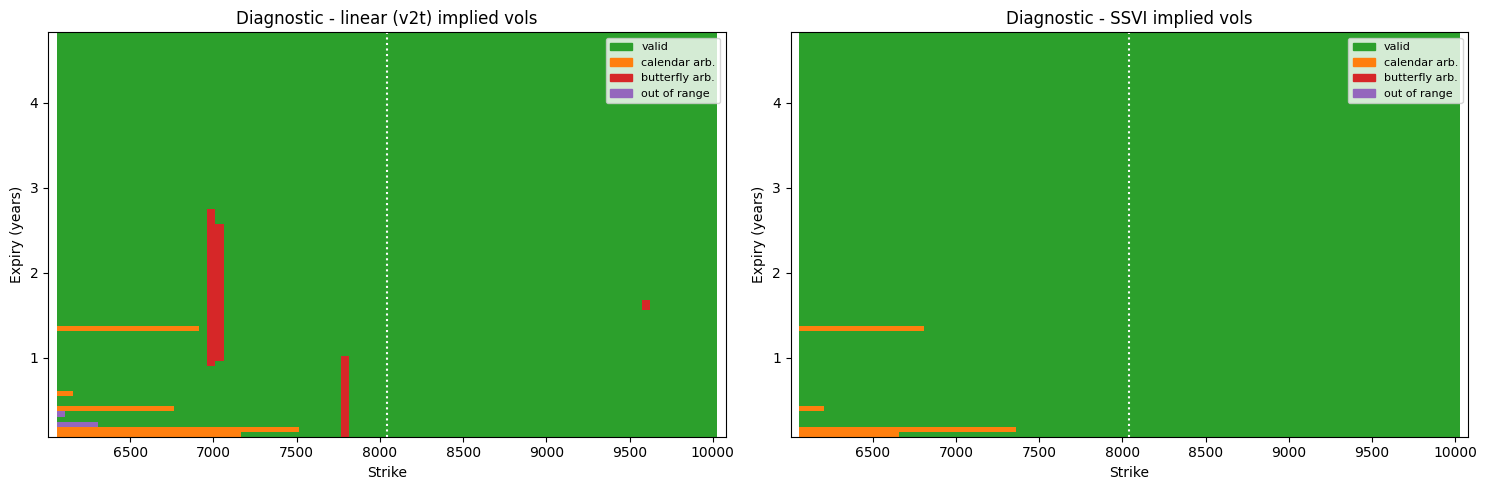

,raw quotes,grid - v2t,grid - SSVI
points,88.0,6320.0,6320.0
valid (%),100.0,97.4,99.1
calendar arbitrage (%),0.0,1.3,0.9
butterfly arbitrage (%),0.0,1.2,0.0
local vol out of range (%),0.0,0.1,0.0


In [31]:
from matplotlib.colors import ListedColormap
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# SSVI implied vol on the same grid, shown (on demand) under the local vol surfaces for comparison
iv_ssvi_grid = np.array([[iv_ssvi(T, K) for K in K_grid] for T in T_grid])


def plot_local_vol_surfaces(surfaces, title, z_max=0.6, show_implied=True, height=650):
    """
    Interactive 3D local vol surfaces (plotly), one per subplot : rotate, zoom, hover to read (K, T, vol).
    surfaces : {subplot title : local variance grid}. Invalid points are holes, values are capped at z_max.
    The SSVI implied vol surface can be switched on / off by clicking its legend entry.
    """
    n = len(surfaces)
    fig = make_subplots(rows=1, cols=n, specs=[[{"type": "scene"}] * n], subplot_titles=list(surfaces.keys()),
                        horizontal_spacing=0.02)
    for col, (name, local_var) in enumerate(surfaces.items(), start=1):
        local_vol = np.minimum(local_vol_from_var(local_var), z_max)
        fig.add_trace(go.Surface(x=K_grid, y=T_grid, z=100 * local_vol, name=f"local vol - {name}",
                                 colorscale="Viridis", cmin=0, cmax=100 * z_max, showscale=(col == 1),
                                 colorbar=dict(title="Vol (%)", x=-0.05),
                                 hovertemplate="K = %{x:.0f}<br>T = %{y:.2f}y<br>local vol = %{z:.2f}%<extra></extra>"),
                      row=1, col=col)
        if show_implied:
            fig.add_trace(go.Surface(x=K_grid, y=T_grid, z=100 * iv_ssvi_grid, name="SSVI implied vol",
                                     colorscale="Greys", showscale=False, opacity=0.5, showlegend=(col == 1),
                                     legendgroup="implied", visible="legendonly",
                                     hovertemplate="K = %{x:.0f}<br>T = %{y:.2f}y<br>implied vol = %{z:.2f}%<extra></extra>"),
                          row=1, col=col)
    fig.update_scenes(xaxis_title="Strike", yaxis_title="Expiry (years)", zaxis_title="Vol (%)",
                      zaxis_range=[0, 100 * z_max], camera_eye=dict(x=-1.6, y=-1.6, z=0.9))
    fig.update_layout(title=title, height=height, margin=dict(l=0, r=0, t=60, b=0),
                      legend=dict(orientation="h", y=-0.02))
    fig.show()


def plot_flags(flags, title, ax):
    """Map of the diagnostic flags on the (K, T) grid."""
    cmap = ListedColormap([flag_colors[f] for f in range(4)])
    ax.pcolormesh(K_grid, T_grid, flags, cmap=cmap, vmin=-0.5, vmax=3.5, shading='nearest')
    handles = [plt.Rectangle((0, 0), 1, 1, color=flag_colors[f]) for f in range(4)]
    ax.legend(handles, flag_labels.values(), loc="upper right", fontsize=8)
    ax.axvline(S0, color="white", linestyle=":")
    ax.set_xlabel("Strike"); ax.set_ylabel("Expiry (years)"); ax.set_title(title)


plot_local_vol_surfaces({"linear (v2t) implied vols": lvar_v2t, "SSVI implied vols": lvar_ssvi},
                        "Dupire local vol from call prices")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_flags(flags_v2t, "Diagnostic - linear (v2t) implied vols", axes[0])
plot_flags(flags_ssvi, "Diagnostic - SSVI implied vols", axes[1])
plt.tight_layout(); plt.show()

pd.concat([diagnostics(raw_dupire["flag"].values, "raw quotes"),
           diagnostics(flags_v2t, "grid - v2t"),
           diagnostics(flags_ssvi, "grid - SSVI")], axis=1).round(1)

**Reading** :
- **v2t** : the implied vol is piecewise linear in $K$, so $\partial_{KK}\sigma$ is zero between the quoted strikes and a Dirac at each of them. In prices, the density $\partial_{KK} C$ gets kinks at every quoted strike : the butterfly failures are lines along the quoted strikes, and the local vol oscillates in between.
- **SSVI** : the surface is $C^\infty$ and free of static arbitrage by construction, so no butterfly failure. The few **calendar** failures sit on the grid points whose central difference in $T$ straddles a listed expiry. The implied borrow + dividend yield $q(T)$ of the forward curve is piecewise constant and jumps at every listed expiry (about 12 % between the April and June 2025 expiries : the CAC40 dividend season) : $F(0,T)$, hence $C(T,K)$, has a kink there, and the finite difference $\partial_T C$ no longer matches the instantaneous $q(T)$ of the numerator. This is specific to the price formulation, where $r$ and $q$ enter explicitly.

**Raw quotes vs. SSVI** : the local vol obtained on the raw quotes is compared with the SSVI local vol at the same $(T, K)$
(bilinear interpolation of the SSVI grid ; nodes outside the grid are dropped).

Raw quotes vs. SSVI local vol on 87 nodes : RMSE = 3.67 vol pts, max |error| = 21.61 vol pts


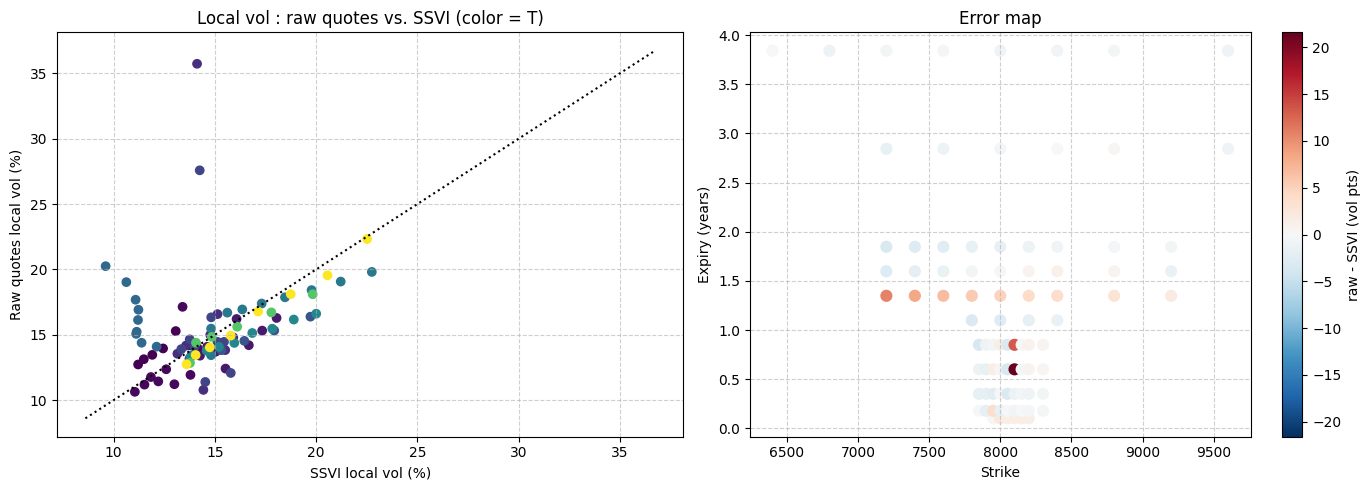

In [32]:
from scipy.interpolate import RegularGridInterpolator

lv_ssvi = local_vol_from_var(lvar_ssvi)
lv_ssvi_interp = RegularGridInterpolator((T_grid, K_grid), lv_ssvi, bounds_error=False, fill_value=np.nan)
raw_dupire["local_vol_ssvi"] = lv_ssvi_interp(raw_dupire[["T", "K"]].values)
raw_dupire["error (vol pts)"] = 100 * (raw_dupire["local_vol"] - raw_dupire["local_vol_ssvi"])

cmp = raw_dupire.dropna(subset=["local_vol", "local_vol_ssvi"])
print(f"Raw quotes vs. SSVI local vol on {len(cmp)} nodes : "
      f"RMSE = {np.sqrt(np.mean(cmp['error (vol pts)']**2)):.2f} vol pts, "
      f"max |error| = {cmp['error (vol pts)'].abs().max():.2f} vol pts")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.scatter(100 * cmp["local_vol_ssvi"], 100 * cmp["local_vol"], c=cmp["T"], cmap="viridis")
lims = [100 * cmp[["local_vol", "local_vol_ssvi"]].min().min() - 1, 100 * cmp[["local_vol", "local_vol_ssvi"]].max().max() + 1]
ax.plot(lims, lims, color="black", linestyle=":")
ax.set_xlabel("SSVI local vol (%)"); ax.set_ylabel("Raw quotes local vol (%)")
ax.set_title("Local vol : raw quotes vs. SSVI (color = T)"); ax.grid(True, linestyle='--', alpha=0.6)
ax = axes[1]
sc = ax.scatter(cmp["K"], cmp["T"], c=cmp["error (vol pts)"], cmap="RdBu_r", s=60,
                vmin=-cmp["error (vol pts)"].abs().max(), vmax=cmp["error (vol pts)"].abs().max())
fig.colorbar(sc, ax=ax, label="raw - SSVI (vol pts)")
ax.set_xlabel("Strike"); ax.set_ylabel("Expiry (years)"); ax.set_title("Error map"); ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout(); plt.show()

### 4.6 Sensitivity to the price noise

Even with the SSVI surface, the price formula is fragile : $\partial_{KK} C$ is the second difference of a quantity of order $10^2 - 10^3$
divided by $dK^2 \approx 2\,500$. Market prices are quoted with a tick size : rounding the SSVI prices to the tick, an error of at most
half a tick, is enough to damage the local vol, and refining the grid makes it **worse** (the error on $\partial_{KK} C$ grows like $\text{tick} / dK^2$).

Rounding to the tick (0.1) : local vol RMSE vs. SSVI = 2.72 vol pts, max error = 35.97 vol pts


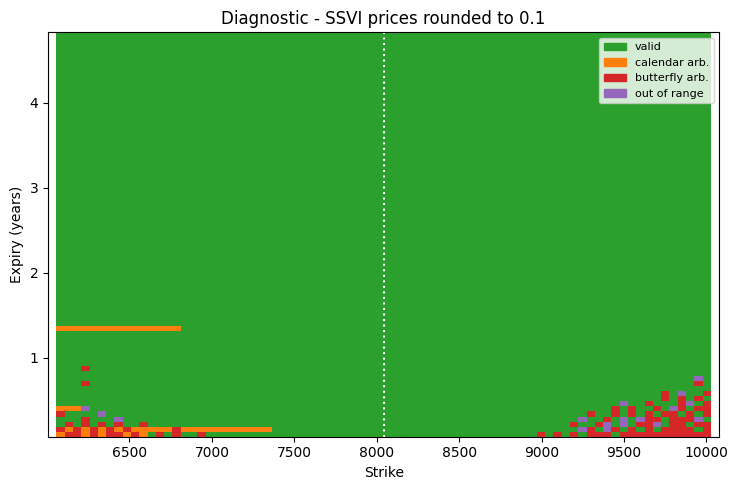

,grid - SSVI rounded
points,6320.0
valid (%),97.7
calendar arbitrage (%),0.7
butterfly arbitrage (%),1.4
local vol out of range (%),0.3


In [33]:
tick = 0.1
C_rounded = np.round(C_ssvi / tick) * tick
num_rnd, den_rnd, lvar_rnd = dupire_from_price_grid(C_rounded, T_grid, K_grid)
flags_rnd = arbitrage_flags(num_rnd, den_rnd, lvar_rnd)

lv_rnd = local_vol_from_var(lvar_rnd)
both = (flags_ssvi == 0) & (flags_rnd == 0)
print(f"Rounding to the tick ({tick}) : local vol RMSE vs. SSVI = {100 * np.sqrt(np.mean((lv_rnd - lv_ssvi)[both]**2)):.2f} vol pts,"
      f" max error = {100 * np.max(np.abs(lv_rnd - lv_ssvi)[both]):.2f} vol pts")

plot_local_vol_surfaces({"SSVI prices": lvar_ssvi, f"SSVI prices rounded to {tick}": lvar_rnd},
                        "Effect of the tick rounding on the Dupire local vol", show_implied=False)

fig, ax = plt.subplots(figsize=(7.5, 5))
plot_flags(flags_rnd, f"Diagnostic - SSVI prices rounded to {tick}", ax)
plt.tight_layout(); plt.show()
diagnostics(flags_rnd, "grid - SSVI rounded").round(1).to_frame()

In [34]:
# Grid refinement : the same rounding, for a finer and finer strike step (strikes within +/- 10% of the spot)
T_test = np.array([0.5, 1.0, 2.0])
rows = []
for n_K in [11, 21, 41, 81, 161]:
    K_test = np.linspace(0.9 * S0, 1.1 * S0, n_K)
    C_exact = call_price_grid(iv_ssvi, T_test, K_test)
    lv_exact = local_vol_from_var(dupire_from_price_grid(C_exact, T_test, K_test)[2])[:, 1:-1]
    num, den, lvar = dupire_from_price_grid(np.round(C_exact / tick) * tick, T_test, K_test)
    flags = arbitrage_flags(num, den, lvar)[:, 1:-1]
    lv_noisy = local_vol_from_var(lvar)[:, 1:-1]
    err = (lv_noisy - lv_exact)[flags == 0]         # error measured on the valid points only
    rows.append({"dK": K_test[1] - K_test[0],
                 "RMSE (vol pts)": 100 * np.sqrt(np.mean(err**2)),
                 "max error (vol pts)": 100 * np.max(np.abs(err)),
                 "invalid points (%)": 100 * np.mean(flags != 0)})
pd.DataFrame(rows).set_index("dK").round(2)

,RMSE (vol pts),max error (vol pts),invalid points (%)
dK,,,
160.843800,0.06,0.15,0.00
80.421900,0.28,0.84,0.00
40.210950,1.61,4.86,0.00
20.105475,2.88,8.40,16.46
10.052738,7.24,14.45,58.70


### 4.7 Local vol vs. implied vol

A consistency check of the SSVI local vol : at short maturity and near the money, the local vol skew is about **twice** the implied vol skew,
$\partial_K \sigma_{loc} \approx 2\,\partial_K \sigma_{imp}$, and the two vols coincide at the money. The rule fades as the maturity grows.

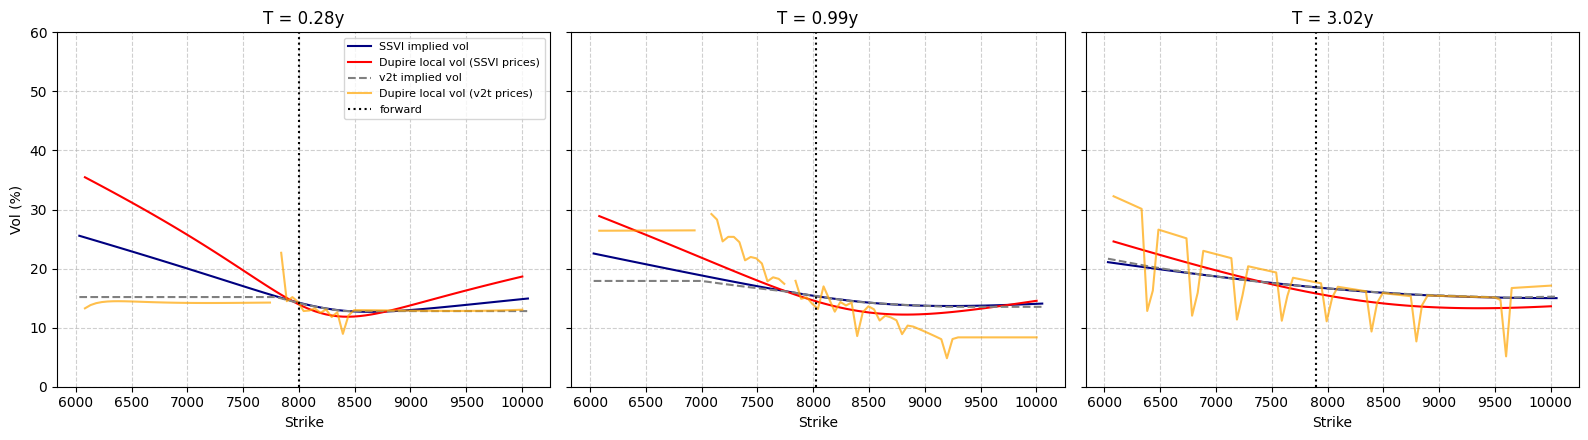

,ATM implied vol (%),ATM local vol (%),skew ratio local / implied
T,,,
0.100000,14.036,12.550,1.594
0.278481,14.270,14.002,1.939
0.516456,14.653,14.471,2.010
0.992405,15.285,14.371,1.954
2.003797,16.565,16.263,2.081
3.015190,16.833,15.806,1.997


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, T_target in zip(axes, [0.25, 1.0, 3.0]):
    i = np.argmin(np.abs(T_grid - T_target))
    T = T_grid[i]
    ax.plot(K_grid, 100 * np.array([iv_ssvi(T, K) for K in K_grid]), color="navy", label="SSVI implied vol")
    ax.plot(K_grid, 100 * lv_ssvi[i], color="red", label="Dupire local vol (SSVI prices)")
    ax.plot(K_grid, 100 * np.array([iv_v2t(T, K) for K in K_grid]), color="grey", linestyle="--", label="v2t implied vol")
    ax.plot(K_grid, 100 * local_vol_from_var(lvar_v2t[i]), color="orange", alpha=0.7, label="Dupire local vol (v2t prices)")
    ax.axvline(forward_curve.calc_forward(T), color="black", linestyle=":", label="forward")
    ax.set_title(f"T = {T:.2f}y"); ax.set_xlabel("Strike"); ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_ylim(0, 60)
axes[0].set_ylabel("Vol (%)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# ATM skew ratio
rows = []
for T_target in [0.1, 0.25, 0.5, 1.0, 2.0, 3.0]:
    i = np.argmin(np.abs(T_grid - T_target))
    T = T_grid[i]
    j = np.argmin(np.abs(K_grid - forward_curve.calc_forward(T)))
    dK2 = K_grid[j + 1] - K_grid[j - 1]
    skew_loc = (lv_ssvi[i, j + 1] - lv_ssvi[i, j - 1]) / dK2
    skew_imp = (iv_ssvi(T, K_grid[j + 1]) - iv_ssvi(T, K_grid[j - 1])) / dK2
    rows.append({"T": T, "ATM implied vol (%)": 100 * iv_ssvi(T, K_grid[j]), "ATM local vol (%)": 100 * lv_ssvi[i, j],
                 "skew ratio local / implied": skew_loc / skew_imp})
pd.DataFrame(rows).set_index("T").round(3)

**Take-aways of the price formulation**
- The formula is exact, but it needs a price surface that is $C^2$ in strike, $C^1$ in time and free of static arbitrage : a linear interpolation of the vols is not.
- Arbitrage-free quotes are not enough either : the raw quotes give a noisy local vol, because the strikes are too sparse for second differences.
- The rates and dividends enter explicitly : the jumps of the implied $q(T)$ create spurious calendar failures at the listed expiries.
- Even on a smooth surface, the tick rounding is amplified by $1/dK^2$ : refining the strike grid makes the local vol **worse**.
- Hence the need to smooth *before* differentiating, and to differentiate a well-scaled quantity in forward moneyness, where $r$ and $q$ disappear : the total implied variance $w(k, T)$ of an SSVI / SVI fit, i.e. the Gatheral formulation (next step).